In [1]:
import re
import pandas as pd
import os
import numpy as np
pd.set_option('display.max_colwidth', 40)
from sklearn.metrics import confusion_matrix, f1_score, cohen_kappa_score
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyClassifier
from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
from scipy.stats import chi2_contingency
from statsmodels.stats.multitest import multipletests
from statsmodels.iolib.summary2 import summary_col
from cycler import cycler

plt.rcParams["axes.prop_cycle"] = cycler(
    color=[
        "#3B7EA1",  # blue
        "#E07A5F",  # coral
        "#81B29A",  # green
        "#F2CC8F",  # sand
        "#6D597A",  # purple
        "#2A9D8F",  # teal
    ]
)
from pathlib import Path
project_dir = Path().resolve()
os.chdir(project_dir)

In [2]:
df = pd.read_csv('post_prediction_corpus.csv')

In [3]:
df["letter_date"] = pd.to_datetime(df["letter_date"], errors="coerce")
# Categorizing letter timing by letter date
df['year'] = df['letter_date'].dt.year
# Grouping the years on the edges with the nearest year data
df["year_group"] = df["year"].replace({
    2017: 2018,
    2026: 2025
})
df["date_numeric"] = (
    pd.to_datetime(df["letter_date"]) 
    - pd.to_datetime(df["letter_date"]).min()
).dt.days

In [4]:
percent_missing = df.isnull().mean() * 100
print(percent_missing)

id_pre                   0.000000
id_post                  0.000000
snippet                  0.000000
case_number              0.000000
letter_date              0.000000
date_inves_complete     32.018927
incident_date           54.942166
complaint_date          47.791798
officer_involved        34.542587
complaint_clean          0.000000
findings_clean           0.000000
f_1                      0.998948
f_2                     57.150368
f_3                     95.425868
f_4                     99.316509
f_5                    100.000000
snippet_clean            0.000000
bias_pred                0.000000
traffic_pred             0.000000
mh_pred                  0.000000
demeanor_pred            0.000000
regulatory_pred          0.000000
nonconcurrence_flag      0.000000
other_finding            0.000000
nothing_pred             0.000000
year                     0.000000
year_group               0.000000
date_numeric             0.000000
dtype: float64


In [5]:
# Percent observations with findings against officers
df['other_finding'].mean()

np.float64(0.20715036803364878)

In [6]:
mask = df['other_finding'] == 1
df.loc[mask, 'nonconcurrence_flag'].mean()

np.float64(0.13705583756345177)

In [7]:
df['other_finding'].value_counts()

other_finding
0.0    1508
1.0     394
Name: count, dtype: int64

## Summary Stats

In [8]:
# How many days are there between complaint and letter date?
for col in ["complaint_date", "letter_date", "date_inves_complete"]:
    df[col] = pd.to_datetime(df[col], errors="coerce")
df["end_date"] = df["letter_date"].fillna(df["date_inves_complete"])
df["days_to_letter"] = (
    df["end_date"] - df["complaint_date"]
).dt.days
avg_days_by_year = (
    df.groupby("year_group")["days_to_letter"]
      .agg(
          average_days="mean",
          median_days="median",
          cases="count"
      )
      .reset_index()
)

avg_days_by_year

,year_group,average_days,median_days,cases
0,2018,124.832536,79.0,209
1,2019,173.224138,141.0,174
2,2020,157.656863,142.5,102
3,2021,195.808989,137.0,89
4,2022,171.315789,164.0,19
5,2023,139.981132,138.0,53
6,2024,176.356061,129.0,132
7,2025,153.381395,131.0,215


In [9]:
df["days_to_letter"].mean()

np.float64(157.77341389728096)

In [10]:
# What proportion of cases have a finding against officers per year?
sustained_by_year = (
    df.groupby("year_group")["other_finding"]
      .mean()
      .reset_index(name="sustained_proportion")
)

sustained_by_year

,year_group,sustained_proportion
0,2018,0.035714
1,2019,0.038043
2,2020,0.027778
3,2021,0.126316
4,2022,0.150327
5,2023,0.148649
6,2024,0.381132
7,2025,0.489362


In [11]:
# What proportion of cases are nonconcurrent per year?
nonconcurrence_by_year = (
    df.groupby("year")["nonconcurrence_flag"]
      .mean()
      .reset_index(name="nonconcurrence_proportion")
)

nonconcurrence_by_year

,year,nonconcurrence_proportion
0,2017,0.000000
1,2018,0.004484
2,2019,0.005435
3,2020,0.000000
4,2021,0.089474
5,2022,0.052288
6,2023,0.016892
7,2024,0.071698
8,2025,0.039568
9,2026,0.000000


In [12]:
cases_per_year = (
    df.groupby("year")["complaint_clean"]
      .count()
      .reset_index(name="total_cases")
)

cases_per_year

,year,total_cases
0,2017,1
1,2018,223
2,2019,184
3,2020,108
4,2021,190
5,2022,306
6,2023,296
7,2024,265
8,2025,278
9,2026,51


In [13]:
mask_nonconcurrence = df["nonconcurrence_flag"] == 1
df.loc[mask_nonconcurrence, "nonconcurrence_flag"].sum()

np.float64(70.0)

In [14]:
mask_finding = df["other_finding"] == 1

nonconcurrence_props_per_year = (
    df[mask_finding]
    .groupby("year")["nonconcurrence_flag"]
    .mean()
    .reset_index(name="nonconcurrence_prop")
)

nonconcurrence_props_per_year

,year,nonconcurrence_prop
0,2018,0.125000
1,2019,0.142857
2,2020,0.000000
3,2021,0.541667
4,2022,0.260870
5,2023,0.113636
6,2024,0.138614
7,2025,0.054422
8,2026,0.000000


In [15]:
pred_cols = [col for col in df.columns if col.endswith("_pred")]

results = []

for col in pred_cols:
    summary = (
        df.groupby("year_group")
        .apply(
            lambda x: pd.Series({
                "predicted_cases": x[col].sum(),
                "total_cases": len(x),
                "sustained_count": x.loc[x[col] == 1, "other_finding"].sum(),
                "nonconcurrences_among_predicted": x.loc[x[col] == 1, "nonconcurrence_flag"].sum(),
                "nonconcurrence_proportion": x.loc[x[col] == 1, "nonconcurrence_flag"].mean()
            }),
            include_groups=False
        )
        .reset_index()
    )
    
    summary["prediction_column"] = col
    results.append(summary)

pred_nonconcurrence_by_year = pd.concat(results, ignore_index=True)

pred_nonconcurrence_by_year

,year_group,predicted_cases,total_cases,sustained_count,nonconcurrences_among_predicted,nonconcurrence_proportion,prediction_column
0,2018,24.0,224.0,0.0,0.0,0.000000,bias_pred
1,2019,7.0,184.0,0.0,0.0,0.000000,bias_pred
2,2020,6.0,108.0,0.0,0.0,0.000000,bias_pred
3,2021,6.0,190.0,1.0,1.0,0.166667,bias_pred
4,2022,23.0,306.0,2.0,0.0,0.000000,bias_pred
5,2023,12.0,296.0,1.0,1.0,0.083333,bias_pred
6,2024,13.0,265.0,5.0,3.0,0.230769,bias_pred
7,2025,15.0,329.0,5.0,0.0,0.000000,bias_pred
8,2018,62.0,224.0,1.0,0.0,0.000000,traffic_pred
9,2019,41.0,184.0,0.0,0.0,0.000000,traffic_pred


In [16]:
# What proportion of cases have none of our variables?
our_cols = [c for c in df.columns if c.endswith("_pred") and c != "nothing_pred"]

df["all_pred_zero"] = (df[our_cols] == 0).all(axis=1)
prop_all_zero_by_year = (
    df.groupby("year_group")["all_pred_zero"]
      .mean()
      .reset_index(name="prop_all_pred_zero")
)

prop_all_zero_by_year

,year_group,prop_all_pred_zero
0,2018,0.383929
1,2019,0.489130
2,2020,0.388889
3,2021,0.452632
4,2022,0.343137
5,2023,0.310811
6,2024,0.339623
7,2025,0.316109


In [17]:
content_cols = ['demeanor_pred', 'regulatory_pred', 'bias_pred']
df["content_pred_zero"] = (df[content_cols] == 0).all(axis=1)
prop_content_zero_by_year = (
    df.groupby("year")["content_pred_zero"]
      .mean()
      .reset_index(name="prop_content_pred_zero")
)

prop_content_zero_by_year

,year,prop_content_pred_zero
0,2017,1.000000
1,2018,0.524664
2,2019,0.608696
3,2020,0.546296
4,2021,0.547368
5,2022,0.434641
6,2023,0.425676
7,2024,0.437736
8,2025,0.431655
9,2026,0.509804


In [18]:
binary_cols = [
    "regulatory_pred",
    "mh_pred",
    "bias_pred",
    "traffic_pred",
    "demeanor_pred"
]

results = []

for i, var1 in enumerate(binary_cols):
    for var2 in binary_cols[i+1:]:
        
        table = pd.crosstab(df[var1], df[var2])
        
        chi2, p, dof, expected = chi2_contingency(table)
        
        results.append({
            "variable_1": var1,
            "variable_2": var2,
            "chi2": chi2.round(2),
            "p_value": p
        })

chi_results = pd.DataFrame(results)
chi_results["p_adjusted"] = multipletests(
    chi_results["p_value"],
    method="fdr_bh"
)[1]
chi_results.sort_values("p_adjusted")

,variable_1,variable_2,chi2,p_value,p_adjusted
2,regulatory_pred,traffic_pred,53.24,2.946323e-13,2.946323e-12
7,bias_pred,traffic_pred,29.50,5.595422e-08,2.797711e-07
5,mh_pred,traffic_pred,15.62,7.760112e-05,2.586704e-04
4,mh_pred,bias_pred,11.20,8.190006e-04,2.047502e-03
0,regulatory_pred,mh_pred,6.79,9.153763e-03,1.830753e-02
9,traffic_pred,demeanor_pred,2.71,9.953669e-02,1.658945e-01
3,regulatory_pred,demeanor_pred,1.80,1.799990e-01,2.571414e-01
6,mh_pred,demeanor_pred,1.29,2.558757e-01,3.198446e-01
8,bias_pred,demeanor_pred,0.80,3.715748e-01,4.128608e-01
1,regulatory_pred,bias_pred,0.00,9.763561e-01,9.763561e-01


In [19]:
chi_results["phi"] = np.sqrt(
    chi_results["chi2"] / len(df)
)
perp = chi_results.sort_values("phi", ascending=False).head()

In [20]:
perp

,variable_1,variable_2,chi2,p_value,p_adjusted,phi
2,regulatory_pred,traffic_pred,53.24,2.946323e-13,2.946323e-12,0.167307
7,bias_pred,traffic_pred,29.50,5.595422e-08,2.797711e-07,0.124539
5,mh_pred,traffic_pred,15.62,7.760112e-05,2.586704e-04,0.090622
4,mh_pred,bias_pred,11.20,8.190006e-04,2.047502e-03,0.076737
0,regulatory_pred,mh_pred,6.79,9.153763e-03,1.830753e-02,0.059749


## Vis

In [21]:
pred_cols = [c for c in df.columns if c.endswith("_pred")]
yearly = (
    df.groupby("year_group")[pred_cols]
      .mean()
)
mean_props = yearly.mean()
max_props = yearly.max()
max_years = yearly.idxmax()
se_props = yearly.std(ddof=1) / np.sqrt(yearly.shape[0])
summary = pd.DataFrame({
    "variable": mean_props.index.str.replace("_pred", "", regex=False),
    "max_prop": max_props.values,
    "max_year": max_years.values,
    "mean_prop": mean_props.values,
    "se": se_props.values
})

summary

,variable,max_prop,max_year,mean_prop,se
0,bias,0.107143,2018,0.055334,0.008756
1,traffic,0.331307,2025,0.255718,0.019643
2,mh,0.107143,2018,0.043997,0.011653
3,demeanor,0.418919,2023,0.380602,0.009893
4,regulatory,0.233962,2024,0.144221,0.020387
5,nothing,0.489130,2019,0.378032,0.022798


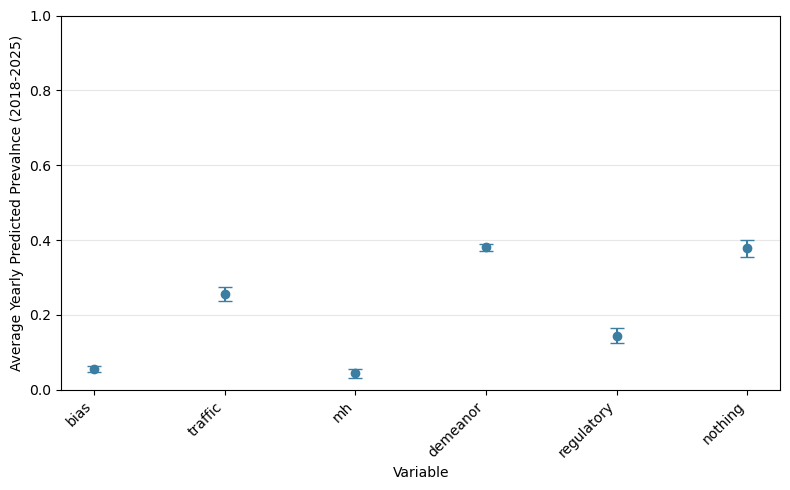

In [22]:
plt.figure(figsize=(8, 5))

plt.errorbar(
    x=summary["variable"],
    y=summary["mean_prop"],
    yerr=summary["se"],
    fmt="o",
    capsize=5,
    elinewidth=1.5
)

plt.ylabel("Average Yearly Predicted Prevalnce (2018-2025)")
plt.xlabel("Variable")
plt.ylim(0, 1)
plt.xticks(rotation=45, ha="right")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

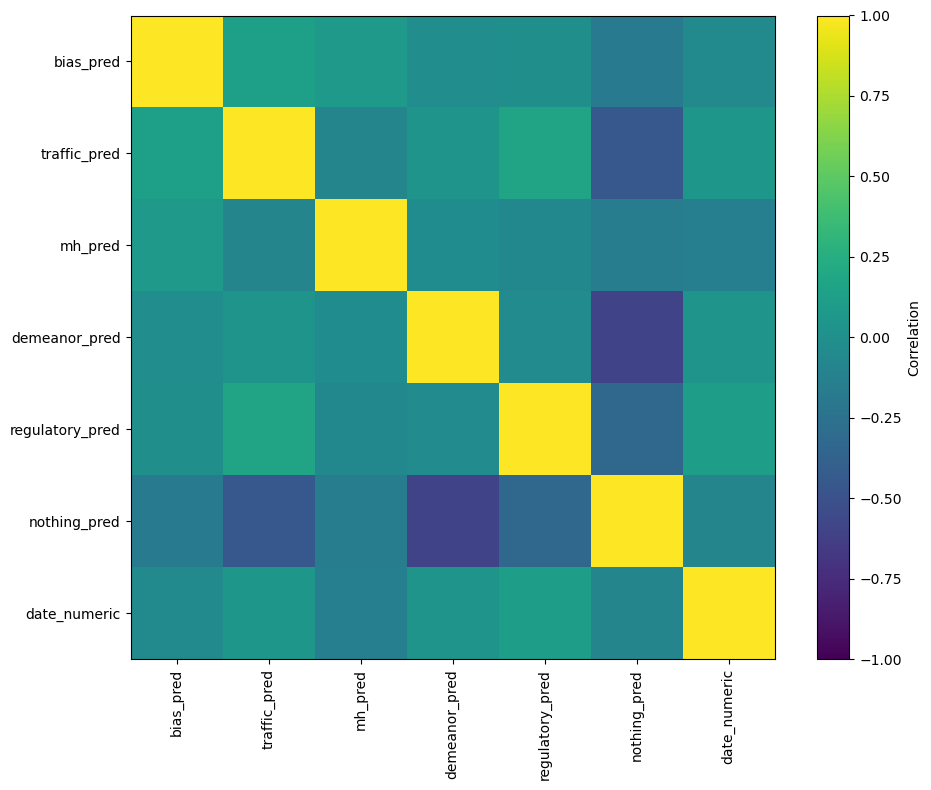

In [23]:
cols = (
    [c for c in df.columns if c.endswith("_pred")]
    + ["date_numeric"]
)

corr_matrix = df[cols].corr()

plt.figure(figsize=(10, 8))
plt.imshow(corr_matrix, vmin=-1, vmax=1)
plt.colorbar(label="Correlation")

plt.xticks(range(len(cols)), cols, rotation=90)
plt.yticks(range(len(cols)), cols)

plt.tight_layout()
plt.show()

In [24]:
overall = (
    df.groupby("year_group")
      .agg(
          total_cases=("year_group", "size"),
          nonconcurrence_prop=("nonconcurrence_flag", "mean"),
          other_finding_prop=("other_finding", "mean")
      )
      .reset_index()
)


pred_cols = [col for col in df.columns if col.endswith("_pred")]

results = []

for col in pred_cols:
    temp = (
        df[df[col] == 1]
        .groupby("year_group")
        .agg(
            predicted_cases=(col, "size"),
            nonconcurrence_prop=("nonconcurrence_flag", "mean"),
            other_finding_prop=("other_finding", "mean")
        )
        .reset_index()
    )
    
    temp["prediction_column"] = col
    results.append(temp)

pred_summary = pd.concat(results, ignore_index=True)

pred_summary

,year_group,predicted_cases,nonconcurrence_prop,other_finding_prop,prediction_column
0,2018,24,0.000000,0.000000,bias_pred
1,2019,7,0.000000,0.000000,bias_pred
2,2020,6,0.000000,0.000000,bias_pred
3,2021,6,0.166667,0.166667,bias_pred
4,2022,23,0.000000,0.086957,bias_pred
5,2023,12,0.083333,0.083333,bias_pred
6,2024,13,0.230769,0.384615,bias_pred
7,2025,15,0.000000,0.333333,bias_pred
8,2018,62,0.000000,0.016129,traffic_pred
9,2019,41,0.000000,0.000000,traffic_pred


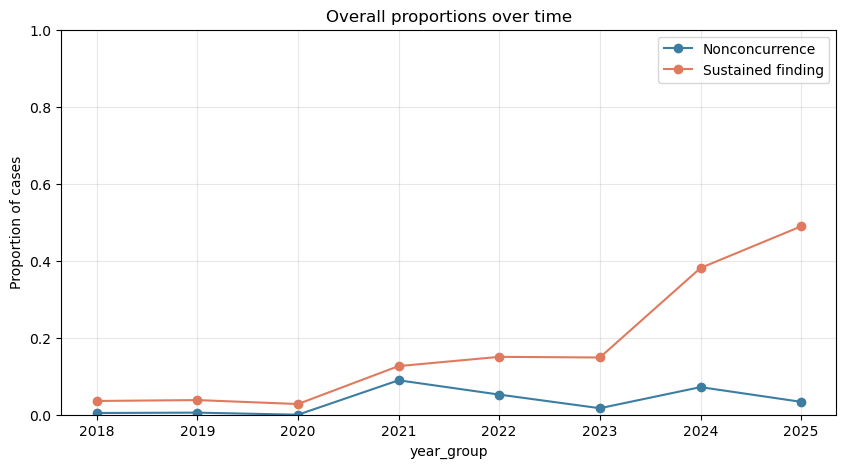

In [25]:
plt.figure(figsize=(10,5))

plt.plot(
    overall["year_group"],
    overall["nonconcurrence_prop"],
    marker="o",
    label="Nonconcurrence"
)

plt.plot(
    overall["year_group"],
    overall["other_finding_prop"],
    marker="o",
    label="Sustained finding"
)

plt.xlabel("year_group")
plt.ylabel("Proportion of cases")
plt.ylim(0,1)
plt.legend()
plt.title("Overall proportions over time")
plt.grid(alpha=0.3)
plt.show()

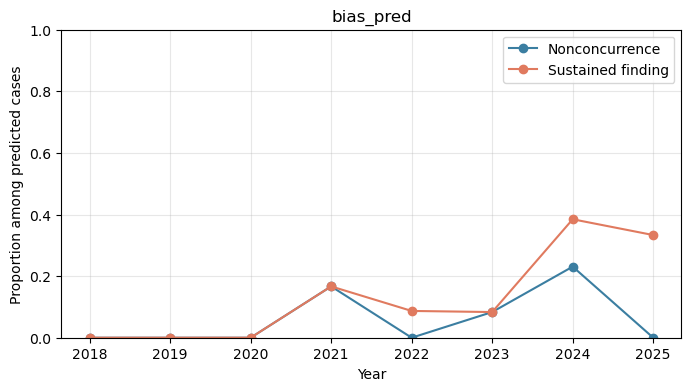

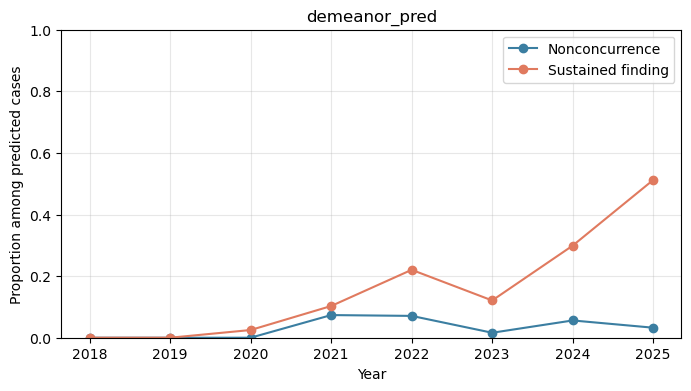

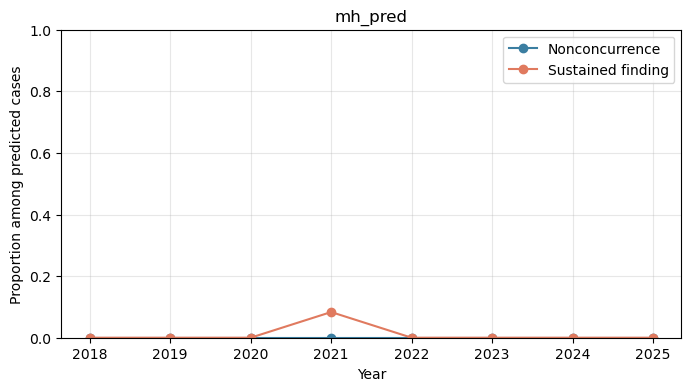

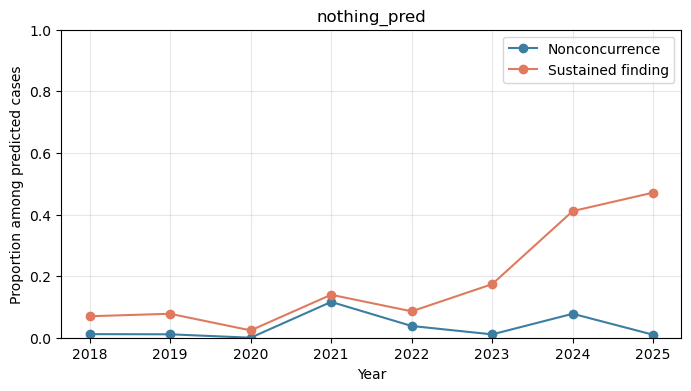

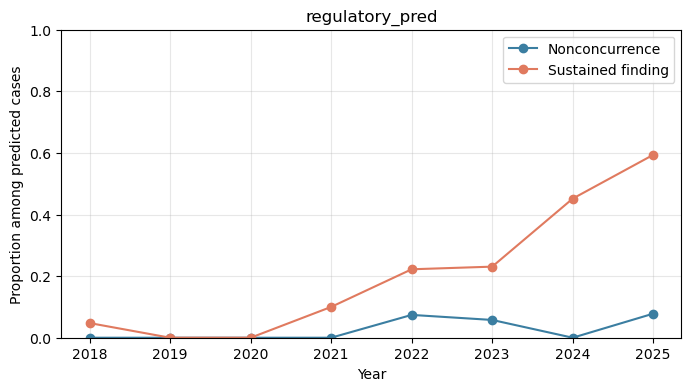

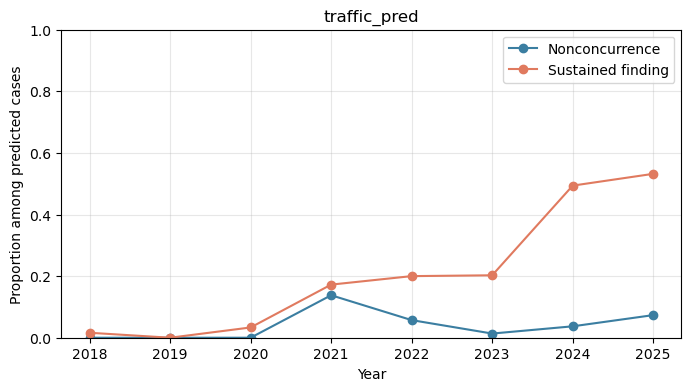

In [26]:
for col, d in pred_summary.groupby("prediction_column"):

    plt.figure(figsize=(8,4))

    plt.plot(
        d["year_group"],
        d["nonconcurrence_prop"],
        marker="o",
        label="Nonconcurrence"
    )

    plt.plot(
        d["year_group"],
        d["other_finding_prop"],
        marker="o",
        label="Sustained finding"
    )

    plt.xlabel("Year")
    plt.ylabel("Proportion among predicted cases")
    plt.ylim(0,1)
    plt.title(col)
    plt.legend()
    plt.grid(alpha=0.3)
    plt.show()

In [27]:
df["letter_date"] = pd.to_datetime(df["letter_date"])

df = df.sort_values("letter_date")

rolling = (
    df.set_index("letter_date")[["nonconcurrence_flag", "other_finding"]]
      .rolling(window="180D", min_periods=10)
      .mean()
      .reset_index()
)

rolling = rolling.rename(columns={
    "nonconcurrence_flag": "nonconcurrence_prop",
    "other_finding": "other_finding_prop"
})

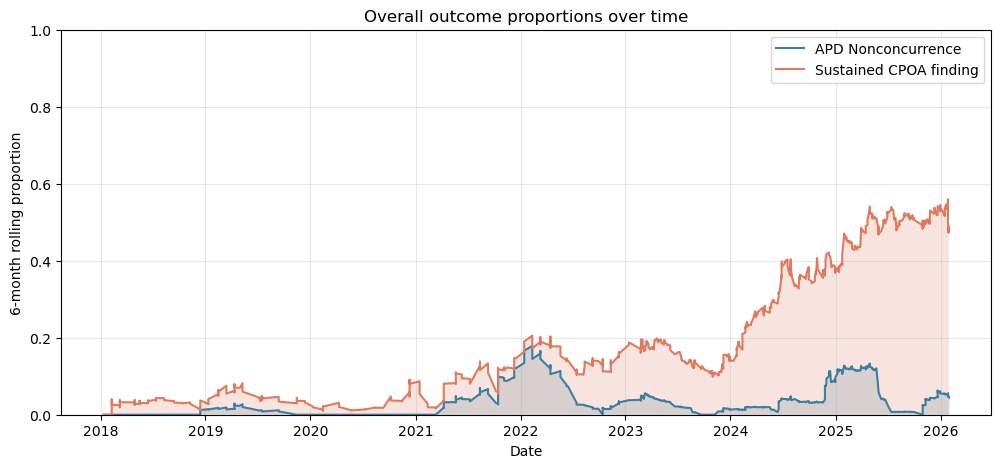

In [28]:
plt.figure(figsize=(12,5))

plt.plot(
    rolling["letter_date"],
    rolling["nonconcurrence_prop"],
    label="APD Nonconcurrence"
)

plt.fill_between(
    rolling["letter_date"],
    rolling["nonconcurrence_prop"],
    alpha=0.2
)

plt.plot(
    rolling["letter_date"],
    rolling["other_finding_prop"],
    label="Sustained CPOA finding"
)

plt.fill_between(
    rolling["letter_date"],
    rolling["other_finding_prop"],
    alpha=0.2
)

plt.xlabel("Date")
plt.ylabel("6-month rolling proportion")
plt.ylim(0,1)
plt.legend()
plt.grid(alpha=0.3)
plt.title("Overall outcome proportions over time")

plt.show()

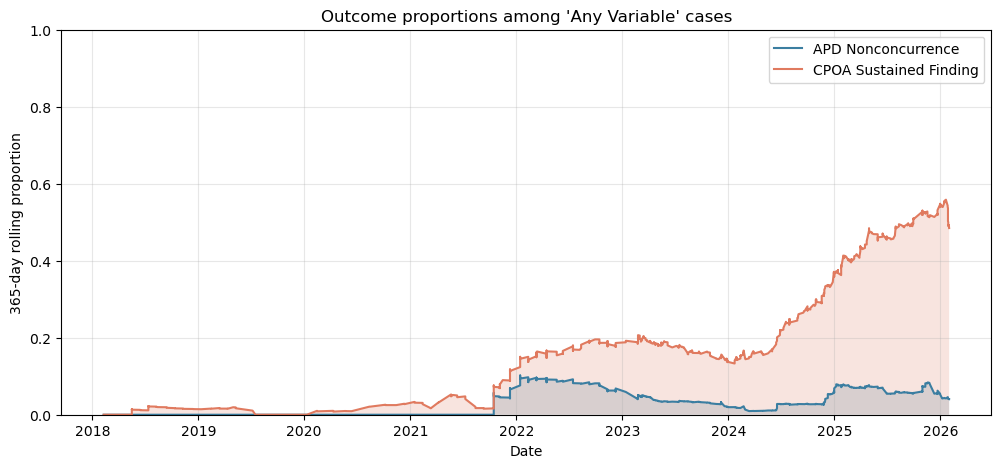

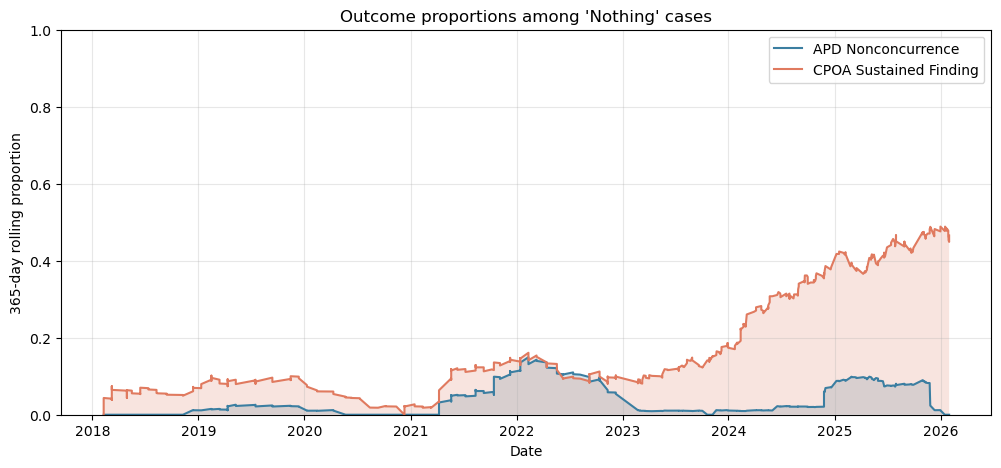

In [29]:
pred_cols = [c for c in df.columns if c.endswith("_pred") and c != "nothing_pred"]

df["letter_date"] = pd.to_datetime(df["letter_date"])
df = df.sort_values("letter_date")

groups = {
    "Any Variable": df[pred_cols].any(axis=1),
    "Nothing": df["nothing_pred"] == 1
}

for label, mask in groups.items():

    temp = (
        df.loc[mask]
          .set_index("letter_date")[["nonconcurrence_flag", "other_finding"]]
          .rolling(window="365D", min_periods=10)
          .mean()
          .reset_index()
          .rename(columns={
              "nonconcurrence_flag": "nonconcurrence_prop",
              "other_finding": "other_finding_prop"
          })
    )

    plt.figure(figsize=(12,5))

    plt.plot(
        temp["letter_date"],
        temp["nonconcurrence_prop"],
        label="APD Nonconcurrence"
    )
    plt.fill_between(
        temp["letter_date"],
        temp["nonconcurrence_prop"],
        alpha=0.2
    )

    plt.plot(
        temp["letter_date"],
        temp["other_finding_prop"],
        label="CPOA Sustained Finding"
    )
    plt.fill_between(
        temp["letter_date"],
        temp["other_finding_prop"],
        alpha=0.2
    )

    plt.title(f"Outcome proportions among '{label}' cases")
    plt.xlabel("Date")
    plt.ylabel("365-day rolling proportion")
    plt.ylim(0, 1)
    plt.legend()
    plt.grid(alpha=0.3)
    plt.show()

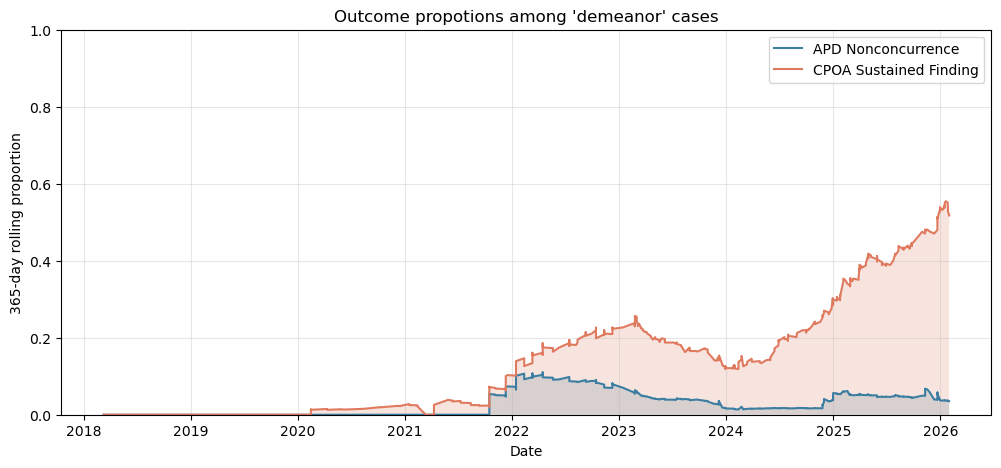

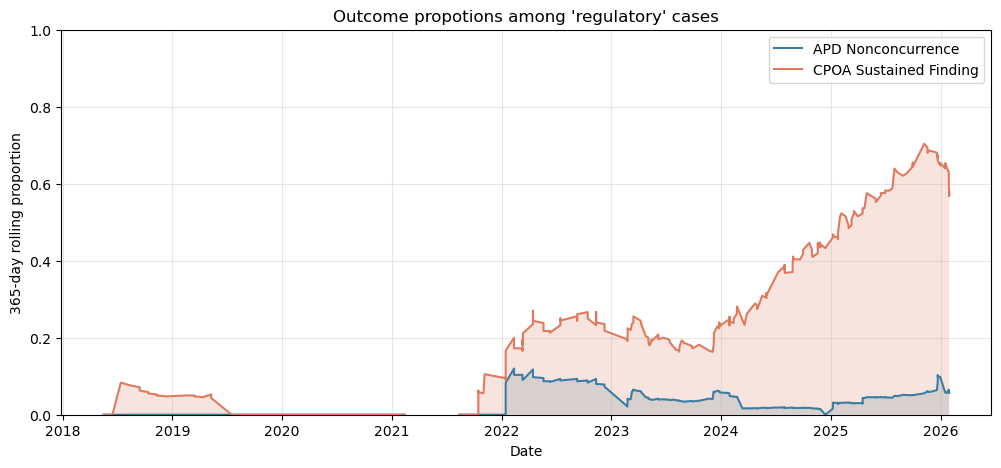

In [30]:
df["letter_date"] = pd.to_datetime(df["letter_date"])
df = df.sort_values("letter_date")

for col in ['demeanor_pred', 'regulatory_pred']:

    temp = (
        df[df[col] == 1]
        .set_index("letter_date")[["nonconcurrence_flag", "other_finding"]]
        .rolling(window="365D", min_periods=10)
        .mean()
        .reset_index()
    )

    temp = temp.rename(columns={
        "nonconcurrence_flag": "nonconcurrence_prop",
        "other_finding": "other_finding_prop"
    })

    plt.figure(figsize=(12,5))

    plt.plot(
        temp["letter_date"],
        temp["nonconcurrence_prop"],
        label="APD Nonconcurrence"
    )

    plt.fill_between(
        temp["letter_date"],
        temp["nonconcurrence_prop"],
        alpha=0.2
    )

    plt.plot(
        temp["letter_date"],
        temp["other_finding_prop"],
        label="CPOA Sustained Finding"
    )

    plt.fill_between(
        temp["letter_date"],
        temp["other_finding_prop"],
        alpha=0.2
    )

    plt.title(f"Outcome propotions among '{col.replace("_pred", "")}' cases")
    plt.xlabel("Date")
    plt.ylabel("365-day rolling proportion")
    plt.ylim(0,1)
    plt.legend()
    plt.grid(alpha=0.3)

    plt.show()

## Stats

In [31]:
df_hc = pd.read_csv("hand_coded_sample_post_cor.csv")
df_hc["letter_date"] = pd.to_datetime(df_hc["letter_date"], errors="coerce", format = "mixed")

In [32]:
df_hc['year'] = df_hc['letter_date'].dt.year
# Group the years on the edges with the nearest year data
df_hc["year_group"] = df_hc["year"].replace({
    2017: 2018,
    2026: 2025
})
df_hc.groupby("year").agg(
    n=("complaint_clean", "size"),
    sustained_count =("other_finding", "sum"),
    mh = ("mental_health", "sum"),
    demeanor = ("demeanor_complaint", "sum"),
    regulatory = ("regulatory_complaint", "sum"),
    traffic = ("traffic_scenario", "sum"),
    bias = ("bias_complaint", "sum"),
    property_ = ("property_complaint", "sum"),
    weapon = ("weapon_complaint", "sum")
)

,n,sustained_count,mh,demeanor,regulatory,traffic,bias,property_,weapon
year,,,,,,,,,
2018.0,22,0,3,7,4,3,2,3,3
2019.0,19,0,1,9,4,4,1,0,0
2020.0,11,0,2,5,1,4,0,0,1
2021.0,19,3,0,5,1,3,2,1,0
2022.0,27,3,1,9,6,4,0,1,0
2023.0,29,1,2,14,6,2,1,3,0
2024.0,24,9,1,7,6,7,2,2,0
2025.0,28,17,0,11,4,3,1,3,1
2026.0,5,1,0,1,1,2,1,1,0


In [33]:
df_hc.columns

Index(['Unnamed: 0', 'filename', 'snippet_raw', 'Location', 'letter_date',
       'incident_date', 'complaint_date', 'investigation_complete_date',
       'jurisdiction_flag', 'duplicative_flag', 'withdrawal_flag',
       'traffic_scenario', 'discipline_recommended', 'property_complaint',
       'property_finding', 'bias_complaint', 'bias_finding',
       'demeanor_complaint', 'demeanor_finding', 'regulatory_complaint',
       'regulatory_finding', 'weapon_complaint', 'weapon_finding',
       'other_finding', 'mental_health', 'nonconcurrence_flag',
       'force_review_board', 'shelly_notes', 'filename_ev', 'pattern',
       'snippet', 'case_number', 'letter_date_ev', 'incident_date_ev',
       'complaint_date_ev', 'disagreement', 'complaint', 'investigation',
       'findings', 'f_1', 'f_2', 'f_3', 'f_4', 'f_5', 'f_6', 'f_7', 'f_8',
       'f_9', 'f_10', 'f_11', 'f_12', 'f_13', 'f_14', 'f_15', 'f_16', 'f_17',
       'f_18', 'f_19', 'f_20', 'findings_clean', 'complaint_clean', 'id_pre'

In [34]:
df.groupby("year").agg(
    n=("complaint_clean", "size"),
    positives=("other_finding", "sum")
)

,n,positives
year,,
2017,1,0.0
2018,223,8.0
2019,184,7.0
2020,108,3.0
2021,190,24.0
2022,306,46.0
2023,296,44.0
2024,265,101.0
2025,278,147.0


### Mental Health Flag 

In [35]:
print(pd.crosstab(
    df["mh_pred"],
    df["other_finding"]
))

n_sample = df[df["mh_pred"] == 1].shape[0]
random_samp= df.sample(n=n_sample, random_state=123)
random_samp["random_group"] = 1

df_random = df.copy()
df_random["random_group"] = 0
df_random.loc[random_samp.index, "random_group"] = 1

print(pd.crosstab(
    df_random["random_group"],
    df_random["other_finding"]
))

other_finding   0.0  1.0
mh_pred                 
0              1436  393
1                72    1
other_finding   0.0  1.0
random_group            
0              1450  379
1                58   15


In [36]:
# creating a 95% confidence interval bootstrap resampling
n_boot = 10000
diffs = []

group1 = df.loc[df["mh_pred"] == 1, "other_finding"]
group0 = df.loc[df["mh_pred"] == 0, "other_finding"]

for i in range(n_boot):
    sample1 = group1.sample(len(group1), replace=True)
    sample0 = group0.sample(len(group0), replace=True)
    diffs.append(sample1.mean() - sample0.mean())

ci = np.percentile(diffs, [2.5, 97.5])

print("Observed difference:", group1.mean() - group0.mean())
print("95% bootstrap CI:", ci)

Observed difference: -0.2011728843518054
95% bootstrap CI: [-0.22908693 -0.16448093]


In [37]:
# Model 1: MENTAL HEALTH ALONE
logit_mh = smf.logit(
    "other_finding ~ mh_pred + date_numeric",
    data=df
).fit()

print(logit_mh.summary())
print("\nOdds ratios:")
print(logit_mh.params.apply(np.exp))

Optimization terminated successfully.
         Current function value: 0.428811
         Iterations 8
                           Logit Regression Results                           
Dep. Variable:          other_finding   No. Observations:                 1902
Model:                          Logit   Df Residuals:                     1899
Method:                           MLE   Df Model:                            2
Date:                Fri, 07 Aug 2026   Pseudo R-squ.:                  0.1595
Time:                        11:21:25   Log-Likelihood:                -815.60
converged:                       True   LL-Null:                       -970.32
Covariance Type:            nonrobust   LLR p-value:                 6.398e-68
                   coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------
Intercept       -4.2703      0.240    -17.823      0.000      -4.740      -3.801
mh_pred         -2.4214

### Demeanor

In [38]:
print(pd.crosstab(
    df["demeanor_pred"],
    df["other_finding"]
))

n_sample = df[df["demeanor_pred"] == 1].shape[0]
random_samp= df.sample(n=n_sample, random_state=123)
random_samp["random_group"] = 1

df_random = df.copy()
df_random["random_group"] = 0
df_random.loc[random_samp.index, "random_group"] = 1

print(pd.crosstab(
    df_random["random_group"],
    df_random["other_finding"]
))

other_finding  0.0  1.0
demeanor_pred          
0              921  248
1              587  146
other_finding  0.0  1.0
random_group           
0              919  250
1              589  144


In [39]:
# creating a 95% confidence interval bootstrap resampling
n_boot = 10000
diffs = []

group1 = df.loc[df["demeanor_pred"] == 1, "other_finding"]
group0 = df.loc[df["demeanor_pred"] == 0, "other_finding"]

for i in range(n_boot):
    sample1 = group1.sample(len(group1), replace=True)
    sample0 = group0.sample(len(group0), replace=True)
    diffs.append(sample1.mean() - sample0.mean())

ci = np.percentile(diffs, [2.5, 97.5])

print("Observed difference:", group1.mean() - group0.mean())
print("95% bootstrap CI:", ci)

Observed difference: -0.012965688190953895
95% bootstrap CI: [-0.04982445  0.02361188]


In [40]:
logit_demeanor = smf.logit(
    "other_finding ~ demeanor_pred + date_numeric",
    data=df
).fit()

print(logit_demeanor.summary())
print("\nOdds ratios:")
print(logit_demeanor.params.apply(np.exp))

Optimization terminated successfully.
         Current function value: 0.431816
         Iterations 7
                           Logit Regression Results                           
Dep. Variable:          other_finding   No. Observations:                 1902
Model:                          Logit   Df Residuals:                     1899
Method:                           MLE   Df Model:                            2
Date:                Fri, 07 Aug 2026   Pseudo R-squ.:                  0.1536
Time:                        11:21:26   Log-Likelihood:                -821.31
converged:                       True   LL-Null:                       -970.32
Covariance Type:            nonrobust   LLR p-value:                 1.943e-65
                    coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------
Intercept        -4.2988      0.242    -17.735      0.000      -4.774      -3.824
demeanor_pred    -0.

In [41]:
logit_demeanor_mh_a = smf.logit(
    "other_finding ~ demeanor_pred + mh_pred + date_numeric",
    data=df
).fit()

print(logit_demeanor_mh_a.summary())
print("\nOdds ratios:")
print(logit_demeanor_mh_a.params.apply(np.exp))

Optimization terminated successfully.
         Current function value: 0.428498
         Iterations 8
                           Logit Regression Results                           
Dep. Variable:          other_finding   No. Observations:                 1902
Model:                          Logit   Df Residuals:                     1898
Method:                           MLE   Df Model:                            3
Date:                Fri, 07 Aug 2026   Pseudo R-squ.:                  0.1601
Time:                        11:21:26   Log-Likelihood:                -815.00
converged:                       True   LL-Null:                       -970.32
Covariance Type:            nonrobust   LLR p-value:                 4.982e-67
                    coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------
Intercept        -4.2187      0.244    -17.323      0.000      -4.696      -3.741
demeanor_pred    -0.

In [42]:
print(pd.crosstab(
    [df["demeanor_pred"],df['traffic_pred']],
    df["other_finding"]
))

other_finding               0.0  1.0
demeanor_pred traffic_pred          
0             0             711  169
              1             210   79
1             0             435   91
              1             152   55


In [43]:
logit_demeanor_tr_a = smf.logit(
    "other_finding ~ demeanor_pred + traffic_pred + date_numeric",
    data=df
).fit()

print(logit_demeanor_tr_a.summary())
print("\nOdds ratios:")
print(logit_demeanor_tr_a.params.apply(np.exp))

Optimization terminated successfully.
         Current function value: 0.429742
         Iterations 7
                           Logit Regression Results                           
Dep. Variable:          other_finding   No. Observations:                 1902
Model:                          Logit   Df Residuals:                     1898
Method:                           MLE   Df Model:                            3
Date:                Fri, 07 Aug 2026   Pseudo R-squ.:                  0.1576
Time:                        11:21:26   Log-Likelihood:                -817.37
converged:                       True   LL-Null:                       -970.32
Covariance Type:            nonrobust   LLR p-value:                 5.268e-66
                    coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------
Intercept        -4.3645      0.244    -17.906      0.000      -4.842      -3.887
demeanor_pred    -0.

In [44]:
logit_demeanor_both_a = smf.logit(
    "other_finding ~ demeanor_pred + traffic_pred + mh_pred + date_numeric",
    data=df
).fit()

print(logit_demeanor_both_a.summary())
print("\nOdds ratios:")
print(logit_demeanor_both_a.params.apply(np.exp))

Optimization terminated successfully.
         Current function value: 0.426779
         Iterations 8
                           Logit Regression Results                           
Dep. Variable:          other_finding   No. Observations:                 1902
Model:                          Logit   Df Residuals:                     1897
Method:                           MLE   Df Model:                            4
Date:                Fri, 07 Aug 2026   Pseudo R-squ.:                  0.1634
Time:                        11:21:26   Log-Likelihood:                -811.73
converged:                       True   LL-Null:                       -970.32
Covariance Type:            nonrobust   LLR p-value:                 2.141e-67
                    coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------
Intercept        -4.2822      0.245    -17.478      0.000      -4.762      -3.802
demeanor_pred    -0.

### regulatory

In [45]:
# Comparing to one random sample of same size:
print(pd.crosstab(
    df["regulatory_pred"],
    df["other_finding"]
))

n_sample = df[df["regulatory_pred"] == 1].shape[0]
random_samp= df.sample(n=n_sample, random_state=123)
random_samp["random_group"] = 1

df_random = df.copy()
df_random["random_group"] = 0
df_random.loc[random_samp.index, "random_group"] = 1

print(pd.crosstab(
    df_random["random_group"],
    df_random["other_finding"]
))

other_finding     0.0  1.0
regulatory_pred           
0                1303  301
1                 205   93
other_finding   0.0  1.0
random_group            
0              1263  341
1               245   53


In [46]:
# creating a 95% confidence interval bootstrap resampling
n_boot = 10000
diffs = []

group1 = df.loc[df["regulatory_pred"] == 1, "other_finding"]
group0 = df.loc[df["regulatory_pred"] == 0, "other_finding"]

for i in range(n_boot):
    sample1 = group1.sample(len(group1), replace=True)
    sample0 = group0.sample(len(group0), replace=True)
    diffs.append(sample1.mean() - sample0.mean())

ci = np.percentile(diffs, [2.5, 97.5])

print("Observed difference:", group1.mean() - group0.mean())
print("95% bootstrap CI:", ci)

Observed difference: 0.12442467656362449
95% bootstrap CI: [0.07010996 0.18123316]


In [47]:
logit_regulatory = smf.logit(
    "other_finding ~ regulatory_pred + date_numeric",
    data=df
).fit()

print(logit_regulatory.summary())
print("\nOdds ratios:")
print(logit_regulatory.params.apply(np.exp))

Optimization terminated successfully.
         Current function value: 0.429783
         Iterations 7
                           Logit Regression Results                           
Dep. Variable:          other_finding   No. Observations:                 1902
Model:                          Logit   Df Residuals:                     1899
Method:                           MLE   Df Model:                            2
Date:                Fri, 07 Aug 2026   Pseudo R-squ.:                  0.1575
Time:                        11:21:27   Log-Likelihood:                -817.45
converged:                       True   LL-Null:                       -970.32
Covariance Type:            nonrobust   LLR p-value:                 4.065e-67
                      coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------
Intercept          -4.4022      0.241    -18.266      0.000      -4.875      -3.930
regulatory_pre

In [48]:
logit_regulatory_mh_a = smf.logit(
    "other_finding ~ regulatory_pred + mh_pred + date_numeric",
    data=df
).fit()

print(logit_regulatory_mh_a.summary())
print("\nOdds ratios:")
print(logit_regulatory_mh_a.params.apply(np.exp))

Optimization terminated successfully.
         Current function value: 0.426740
         Iterations 8
                           Logit Regression Results                           
Dep. Variable:          other_finding   No. Observations:                 1902
Model:                          Logit   Df Residuals:                     1898
Method:                           MLE   Df Model:                            3
Date:                Fri, 07 Aug 2026   Pseudo R-squ.:                  0.1635
Time:                        11:21:27   Log-Likelihood:                -811.66
converged:                       True   LL-Null:                       -970.32
Covariance Type:            nonrobust   LLR p-value:                 1.778e-68
                      coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------
Intercept          -4.3221      0.242    -17.860      0.000      -4.796      -3.848
regulatory_pre

In [49]:
print(pd.crosstab(
    [df["regulatory_pred"],df['traffic_pred']],
    df["other_finding"]
))

other_finding                  0.0  1.0
regulatory_pred traffic_pred           
0               0             1017  220
                1              286   81
1               0              129   40
                1               76   53


In [50]:
logit_regulatory_tr_a = smf.logit(
    "other_finding ~ regulatory_pred + traffic_pred + date_numeric",
    data=df
).fit()

print(logit_regulatory_tr_a.summary())
print("\nOdds ratios:")
print(logit_regulatory_tr_a.params.apply(np.exp))

Optimization terminated successfully.
         Current function value: 0.428369
         Iterations 7
                           Logit Regression Results                           
Dep. Variable:          other_finding   No. Observations:                 1902
Model:                          Logit   Df Residuals:                     1898
Method:                           MLE   Df Model:                            3
Date:                Fri, 07 Aug 2026   Pseudo R-squ.:                  0.1603
Time:                        11:21:27   Log-Likelihood:                -814.76
converged:                       True   LL-Null:                       -970.32
Covariance Type:            nonrobust   LLR p-value:                 3.899e-67
                      coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------
Intercept          -4.4502      0.242    -18.420      0.000      -4.924      -3.977
regulatory_pre

In [51]:
logit_regulatory_both_a = smf.logit(
    "other_finding ~ regulatory_pred + traffic_pred + mh_pred + date_numeric",
    data=df
).fit()

print(logit_regulatory_both_a.summary())
print("\nOdds ratios:")
print(logit_regulatory_both_a.params.apply(np.exp))

Optimization terminated successfully.
         Current function value: 0.425576
         Iterations 8
                           Logit Regression Results                           
Dep. Variable:          other_finding   No. Observations:                 1902
Model:                          Logit   Df Residuals:                     1897
Method:                           MLE   Df Model:                            4
Date:                Fri, 07 Aug 2026   Pseudo R-squ.:                  0.1658
Time:                        11:21:27   Log-Likelihood:                -809.45
converged:                       True   LL-Null:                       -970.32
Covariance Type:            nonrobust   LLR p-value:                 2.206e-68
                      coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------
Intercept          -4.3688      0.243    -17.996      0.000      -4.845      -3.893
regulatory_pre

In [52]:
logit_regulatory_tr_m = smf.logit(
    "other_finding ~ regulatory_pred*traffic_pred + date_numeric",
    data=df
).fit()

print(logit_regulatory_tr_m.summary())
print("\nOdds ratios:")
print(logit_regulatory_tr_m.params.apply(np.exp))

Optimization terminated successfully.
         Current function value: 0.427520
         Iterations 7
                           Logit Regression Results                           
Dep. Variable:          other_finding   No. Observations:                 1902
Model:                          Logit   Df Residuals:                     1897
Method:                           MLE   Df Model:                            4
Date:                Fri, 07 Aug 2026   Pseudo R-squ.:                  0.1620
Time:                        11:21:27   Log-Likelihood:                -813.14
converged:                       True   LL-Null:                       -970.32
Covariance Type:            nonrobust   LLR p-value:                 8.685e-67
                                   coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------------------
Intercept                       -4.4123      0.242    -18.235      0.000

### bias

In [53]:
print(pd.crosstab(
    df["bias_pred"],
    df["other_finding"]
))

n_sample = df[df["bias_pred"] == 1].shape[0]
random_samp= df.sample(n=n_sample, random_state=123)
random_samp["random_group"] = 1

df_random = df.copy()
df_random["random_group"] = 0
df_random.loc[random_samp.index, "random_group"] = 1

print(pd.crosstab(
    df_random["random_group"],
    df_random["other_finding"]
))

other_finding   0.0  1.0
bias_pred               
0              1416  380
1                92   14
other_finding   0.0  1.0
random_group            
0              1422  374
1                86   20


In [54]:
# creating a 95% confidence interval bootstrap resampling
n_boot = 10000
diffs = []

group1 = df.loc[df["bias_pred"] == 1, "other_finding"]
group0 = df.loc[df["bias_pred"] == 0, "other_finding"]

for i in range(n_boot):
    sample1 = group1.sample(len(group1), replace=True)
    sample0 = group0.sample(len(group0), replace=True)
    diffs.append(sample1.mean() - sample0.mean())

ci = np.percentile(diffs, [2.5, 97.5])

print("Observed difference:", group1.mean() - group0.mean())
print("95% bootstrap CI:", ci)

Observed difference: -0.07950582006135226
95% bootstrap CI: [-0.14282262 -0.00957053]


In [55]:
logit_bias = smf.logit(
    "other_finding ~ bias_pred + date_numeric",
    data=df
).fit()

print(logit_bias.summary())
print("\nOdds ratios:")
print(logit_bias.params.apply(np.exp))

Optimization terminated successfully.
         Current function value: 0.431409
         Iterations 7
                           Logit Regression Results                           
Dep. Variable:          other_finding   No. Observations:                 1902
Model:                          Logit   Df Residuals:                     1899
Method:                           MLE   Df Model:                            2
Date:                Fri, 07 Aug 2026   Pseudo R-squ.:                  0.1544
Time:                        11:21:28   Log-Likelihood:                -820.54
converged:                       True   LL-Null:                       -970.32
Covariance Type:            nonrobust   LLR p-value:                 8.963e-66
                   coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------
Intercept       -4.3254      0.239    -18.091      0.000      -4.794      -3.857
bias_pred       -0.4919

In [56]:
pd.crosstab(
    [df["bias_pred"], df["traffic_pred"]],
    df["other_finding"]
)

other_finding            0.0  1.0
bias_pred traffic_pred           
0         0             1098  254
          1              318  126
1         0               48    6
          1               44    8

In [57]:
logit_bias_mh_a = smf.logit(
    "other_finding ~ bias_pred + mh_pred + date_numeric",
    data=df
).fit()

print(logit_bias_mh_a.summary())
print("\nOdds ratios:")
print(logit_bias_mh_a.params.apply(np.exp))

Optimization terminated successfully.
         Current function value: 0.428264
         Iterations 8
                           Logit Regression Results                           
Dep. Variable:          other_finding   No. Observations:                 1902
Model:                          Logit   Df Residuals:                     1898
Method:                           MLE   Df Model:                            3
Date:                Fri, 07 Aug 2026   Pseudo R-squ.:                  0.1605
Time:                        11:21:28   Log-Likelihood:                -814.56
converged:                       True   LL-Null:                       -970.32
Covariance Type:            nonrobust   LLR p-value:                 3.194e-67
                   coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------
Intercept       -4.2498      0.240    -17.705      0.000      -4.720      -3.779
bias_pred       -0.4375

In [58]:
print(pd.crosstab(
    [df["bias_pred"],df['traffic_pred']],
    df["other_finding"]
))

other_finding            0.0  1.0
bias_pred traffic_pred           
0         0             1098  254
          1              318  126
1         0               48    6
          1               44    8


In [59]:
logit_bias_tr_a = smf.logit(
    "other_finding ~ bias_pred + traffic_pred + date_numeric",
    data=df
).fit()

print(logit_bias_tr_a.summary())
print("\nOdds ratios:")
print(logit_bias_tr_a.params.apply(np.exp))

Optimization terminated successfully.
         Current function value: 0.429091
         Iterations 7
                           Logit Regression Results                           
Dep. Variable:          other_finding   No. Observations:                 1902
Model:                          Logit   Df Residuals:                     1898
Method:                           MLE   Df Model:                            3
Date:                Fri, 07 Aug 2026   Pseudo R-squ.:                  0.1589
Time:                        11:21:28   Log-Likelihood:                -816.13
converged:                       True   LL-Null:                       -970.32
Covariance Type:            nonrobust   LLR p-value:                 1.533e-66
                   coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------
Intercept       -4.3912      0.240    -18.280      0.000      -4.862      -3.920
bias_pred       -0.5706

In [60]:
logit_bias_both_a = smf.logit(
    "other_finding ~ bias_pred + traffic_pred + mh_pred + date_numeric",
    data=df
).fit()

print(logit_bias_both_a.summary())
print("\nOdds ratios:")
print(logit_bias_both_a.params.apply(np.exp))

Optimization terminated successfully.
         Current function value: 0.426334
         Iterations 8
                           Logit Regression Results                           
Dep. Variable:          other_finding   No. Observations:                 1902
Model:                          Logit   Df Residuals:                     1897
Method:                           MLE   Df Model:                            4
Date:                Fri, 07 Aug 2026   Pseudo R-squ.:                  0.1643
Time:                        11:21:28   Log-Likelihood:                -810.89
converged:                       True   LL-Null:                       -970.32
Covariance Type:            nonrobust   LLR p-value:                 9.228e-68
                   coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------
Intercept       -4.3141      0.241    -17.880      0.000      -4.787      -3.841
bias_pred       -0.5159

### traffic

In [61]:
# Comparing to one random sample of same size:
print(pd.crosstab(
    df["traffic_pred"],
    df["other_finding"]
))

n_sample = df[df["traffic_pred"] == 1].shape[0]
random_samp= df.sample(n=n_sample, random_state=123)
random_samp["random_group"] = 1

df_random = df.copy()
df_random["random_group"] = 0
df_random.loc[random_samp.index, "random_group"] = 1

print(pd.crosstab(
    df_random["random_group"],
    df_random["other_finding"]
))

other_finding   0.0  1.0
traffic_pred            
0              1146  260
1               362  134
other_finding   0.0  1.0
random_group            
0              1106  300
1               402   94


In [62]:
# creating a 95% confidence interval bootstrap resampling
n_boot = 10000
diffs = []

group1 = df.loc[df["traffic_pred"] == 1, "other_finding"]
group0 = df.loc[df["traffic_pred"] == 0, "other_finding"]

for i in range(n_boot):
    sample1 = group1.sample(len(group1), replace=True)
    sample0 = group0.sample(len(group0), replace=True)
    diffs.append(sample1.mean() - sample0.mean())

ci = np.percentile(diffs, [2.5, 97.5])

print("Observed difference:", group1.mean() - group0.mean())
print("95% bootstrap CI:", ci)

Observed difference: 0.08523952645344834
95% bootstrap CI: [0.04087644 0.12934773]


In [63]:
logit_traffic = smf.logit(
    "other_finding ~ traffic_pred + date_numeric",
    data=df
).fit()

print(logit_traffic.summary())
print("\nOdds ratios:")
print(logit_traffic.params.apply(np.exp))

Optimization terminated successfully.
         Current function value: 0.430044
         Iterations 7
                           Logit Regression Results                           
Dep. Variable:          other_finding   No. Observations:                 1902
Model:                          Logit   Df Residuals:                     1899
Method:                           MLE   Df Model:                            2
Date:                Fri, 07 Aug 2026   Pseudo R-squ.:                  0.1570
Time:                        11:21:29   Log-Likelihood:                -817.94
converged:                       True   LL-Null:                       -970.32
Covariance Type:            nonrobust   LLR p-value:                 6.680e-67
                   coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------
Intercept       -4.4161      0.240    -18.419      0.000      -4.886      -3.946
traffic_pred     0.3777

In [64]:
print(pd.crosstab(
    [df["mh_pred"],df['traffic_pred']],
    df["other_finding"]
))

other_finding          0.0  1.0
mh_pred traffic_pred           
0       0             1078  259
        1              358  134
1       0               68    1
        1                4    0


In [65]:
logit_traffic_mh_a = smf.logit(
    "other_finding ~ traffic_pred + mh_pred + date_numeric",
    data=df
).fit()

print(logit_traffic_mh_a.summary())
print("\nOdds ratios:")
print(logit_traffic_mh_a.params.apply(np.exp))

Optimization terminated successfully.
         Current function value: 0.427096
         Iterations 8
                           Logit Regression Results                           
Dep. Variable:          other_finding   No. Observations:                 1902
Model:                          Logit   Df Residuals:                     1898
Method:                           MLE   Df Model:                            3
Date:                Fri, 07 Aug 2026   Pseudo R-squ.:                  0.1628
Time:                        11:21:29   Log-Likelihood:                -812.34
converged:                       True   LL-Null:                       -970.32
Covariance Type:            nonrobust   LLR p-value:                 3.488e-68
                   coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------
Intercept       -4.3353      0.241    -17.991      0.000      -4.808      -3.863
traffic_pred     0.3438

### nothing

In [66]:
logit_nothing = smf.logit(
    "other_finding ~ nothing_pred + date_numeric",
    data=df
).fit()

print(logit_nothing.summary())
print("\nOdds ratios:")
print(logit_nothing.params.apply(np.exp))

Optimization terminated successfully.
         Current function value: 0.432008
         Iterations 7
                           Logit Regression Results                           
Dep. Variable:          other_finding   No. Observations:                 1902
Model:                          Logit   Df Residuals:                     1899
Method:                           MLE   Df Model:                            2
Date:                Fri, 07 Aug 2026   Pseudo R-squ.:                  0.1532
Time:                        11:21:29   Log-Likelihood:                -821.68
converged:                       True   LL-Null:                       -970.32
Covariance Type:            nonrobust   LLR p-value:                 2.798e-65
                   coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------
Intercept       -4.3867      0.246    -17.820      0.000      -4.869      -3.904
nothing_pred     0.0824